# 20 · Auditoría de predicciones guardadas — tesis precio de bolsa

**Sin entrenamientos.** Lee exclusivamente los archivos exportados por el notebook 19, verifica integridad y comparabilidad, calcula desempeño relativo a persistencia, intervalos probabilísticos, sensibilidad a errores extremos y contrastes pareados con remuestreo en bloques de orígenes.

**Límites:** el remuestreo en bloques es un análisis de sensibilidad, no prueba definitiva de superioridad; la cobertura nominal 80 % no garantiza calibración; las bandas LSTM recursivas son *plug-in* y la GRU bayesiana representa sobre todo incertidumbre paramétrica. Los escenarios *oracle* se presentan separados y no son operativos. Este notebook no repara predicciones ya guardadas ni reemplaza una auditoría de código y disponibilidad temporal de variables.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 25)

def raiz_repo():
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p/'reports'/'comparacion_definitiva_horizontes_exactos').exists():
            return p
    raise FileNotFoundError('No encuentro reports/comparacion_definitiva_horizontes_exactos. Abre este notebook dentro del proyecto tesis-bolsa.')
ROOT=raiz_repo()
SOURCE=ROOT/'reports'/'comparacion_definitiva_horizontes_exactos'
OUT=ROOT/'reports'/'auditoria_predicciones_guardadas'
OUT.mkdir(parents=True,exist_ok=True)
PRED=SOURCE/'predicciones_todos.parquet'
if not PRED.exists():
    raise FileNotFoundError(f'Falta {PRED}. Ejecuta el notebook 19 hasta la sección 6 o copia el archivo exportado.')
raw=pd.read_parquet(PRED)
print('Archivo:',PRED,'\nFilas:',len(raw),'\nColumnas:',list(raw.columns))
print('Salida:',OUT)


Archivo: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_definitiva_horizontes_exactos/predicciones_todos.parquet 
Filas: 47385 
Columnas: ['fecha', 'Modelo', 'Horizonte', 'real', 'pred', 'p10', 'p50', 'p90', 'std', 'Origen_incertidumbre', 'origen']
Salida: /Users/maguverm/Documents/tesis-bolsa/reports/auditoria_predicciones_guardadas


## 1 · Integridad y comparabilidad: detener si algo no cuadra

In [2]:
required={'fecha','origen','Modelo','Horizonte','real','pred','p10','p50','p90'}
missing=required-set(raw.columns)
assert not missing, f'Faltan columnas: {missing}'
df=raw.copy()
df['fecha']=pd.to_datetime(df['fecha']);df['origen']=pd.to_datetime(df['origen'])
df['Horizonte']=pd.to_numeric(df['Horizonte']).astype(int)
for c in ['real','pred','p10','p50','p90']:
    df[c]=pd.to_numeric(df[c],errors='coerce')
assert not df.duplicated(['Modelo','Horizonte','origen']).any(), 'Predicciones duplicadas por modelo, horizonte y origen'
assert ((df.fecha-df.origen).dt.days==df.Horizonte).all(), 'Error: fechas no corresponden a t+h'
assert df[['real','pred']].notna().all().all(), 'Hay predicciones o valores reales faltantes'
assert np.isfinite(df[['real','pred']].to_numpy()).all(), 'Valores no finitos'
assert set(range(1,16)).issubset(set(df.Horizonte.unique())), 'Faltan horizontes de 1 a 15'

operativos=['SARIMAX','SARIMAX sin semana','LSTM cuantílica','TFT + covariables','GRU Bayesiana','Persistencia','Persistencia semanal']
oracle=[m for m in df.Modelo.unique() if '[oracle]' in str(m)]
assert set(operativos).issubset(set(df.Modelo.unique())), f'Faltan modelos: {set(operativos)-set(df.Modelo.unique())}'
base=df[df.Modelo.isin(operativos)].copy()
conteos=base.groupby(['Modelo','Horizonte']).agg(N=('real','size'),n_origen=('origen','nunique')).reset_index()
assert (conteos.N==conteos.n_origen).all()
assert conteos.N.nunique()==1, 'Número desigual de orígenes entre modelos/horizontes'
for h,g in base.groupby('Horizonte'):
    ref=None
    for m,z in g.groupby('Modelo'):
        zz=z.set_index('origen').sort_index()
        if ref is None:ref=zz[['fecha','real']]
        else:
            assert zz.index.equals(ref.index),f'Orígenes distintos en h={h}: {m}'
            assert zz.fecha.equals(ref.fecha),f'Fechas distintas en h={h}: {m}'
            assert np.allclose(zz.real,ref.real),f'Valores reales distintos en h={h}: {m}'
print('VALIDACIÓN SUPERADA:',len(base),'filas; ',conteos.N.iloc[0],'orígenes por modelo/horizonte')
print('Escenarios oracle disponibles:',oracle)
display(conteos.pivot(index='Horizonte',columns='Modelo',values='N'))
conteos.to_csv(OUT/'integridad_conteos.csv',index=False)


VALIDACIÓN SUPERADA: 36855 filas;  351 orígenes por modelo/horizonte
Escenarios oracle disponibles: ['SARIMAX [oracle]', 'SARIMAX sin semana [oracle]']


Modelo,GRU Bayesiana,LSTM cuantílica,Persistencia,Persistencia semanal,SARIMAX,SARIMAX sin semana,TFT + covariables
Horizonte,,,,,,,
1,351,351,351,351,351,351,351
2,351,351,351,351,351,351,351
3,351,351,351,351,351,351,351
4,351,351,351,351,351,351,351
5,351,351,351,351,351,351,351
6,351,351,351,351,351,351,351
7,351,351,351,351,351,351,351
8,351,351,351,351,351,351,351
9,351,351,351,351,351,351,351


## 2 · Métricas puntuales y mejora relativa a persistencia

In [3]:
def metrics(g):
    y=g.real.to_numpy(float);p=g.pred.to_numpy(float)
    e=p-y
    return {'N':len(g),'MAE':np.abs(e).mean(),'RMSE':np.sqrt(np.mean(e**2)),
            'Sesgo':e.mean(),'MedAE':np.median(np.abs(e)),
            'P95_error_abs':np.quantile(np.abs(e),.95),
            'MaxError':np.abs(e).max(),
            'MAPE_pct':np.mean(np.abs(e)/np.maximum(np.abs(y),1e-8))*100}
rows=[]
for (m,h),g in base.groupby(['Modelo','Horizonte']):rows.append({'Modelo':m,'Horizonte':h,**metrics(g)})
met=pd.DataFrame(rows)
ref=met[met.Modelo=='Persistencia'][['Horizonte','RMSE','MAE']].rename(columns={'RMSE':'RMSE_persistencia','MAE':'MAE_persistencia'})
met=met.merge(ref,on='Horizonte',validate='many_to_one')
met['Skill_RMSE_pct']=100*(1-met.RMSE/met.RMSE_persistencia)
met['Skill_MAE_pct']=100*(1-met.MAE/met.MAE_persistencia)
met.to_csv(OUT/'metricas_y_skill.csv',index=False)
met.to_parquet(OUT/'metricas_y_skill.parquet',index=False)
display(met.pivot(index='Horizonte',columns='Modelo',values='RMSE').round(2))
display(met.pivot(index='Horizonte',columns='Modelo',values='Skill_RMSE_pct').round(2))


Modelo,GRU Bayesiana,LSTM cuantílica,Persistencia,Persistencia semanal,SARIMAX,SARIMAX sin semana,TFT + covariables
Horizonte,,,,,,,
1,55.01,55.15,55.57,120.07,55.95,56.66,53.65
2,75.77,77.60,79.32,120.04,78.79,79.81,95.63
3,87.89,90.66,93.51,120.05,92.53,93.37,85.79
4,99.67,100.84,104.34,120.06,103.17,103.66,95.16
5,113.95,108.45,112.30,120.11,111.40,111.58,104.65
6,121.16,111.74,115.20,120.08,116.24,116.00,110.24
7,128.04,117.48,120.27,120.27,123.38,123.02,127.04
8,131.66,127.00,130.93,161.77,134.36,133.82,139.52
9,153.93,136.03,141.69,161.80,144.45,143.73,144.91


Modelo,GRU Bayesiana,LSTM cuantílica,Persistencia,Persistencia semanal,SARIMAX,SARIMAX sin semana,TFT + covariables
Horizonte,,,,,,,
1,1.01,0.76,0.0,-116.08,-0.68,-1.95,3.46
2,4.48,2.17,0.0,-51.34,0.67,-0.61,-20.56
3,6.01,3.05,0.0,-28.39,1.04,0.15,8.25
4,4.48,3.36,0.0,-15.06,1.13,0.65,8.80
5,-1.47,3.43,0.0,-6.96,0.80,0.64,6.81
6,-5.17,3.00,0.0,-4.24,-0.90,-0.69,4.31
7,-6.46,2.32,0.0,0.00,-2.59,-2.29,-5.63
8,-0.55,3.00,0.0,-23.55,-2.62,-2.20,-6.56
9,-8.63,4.00,0.0,-14.19,-1.94,-1.43,-2.27


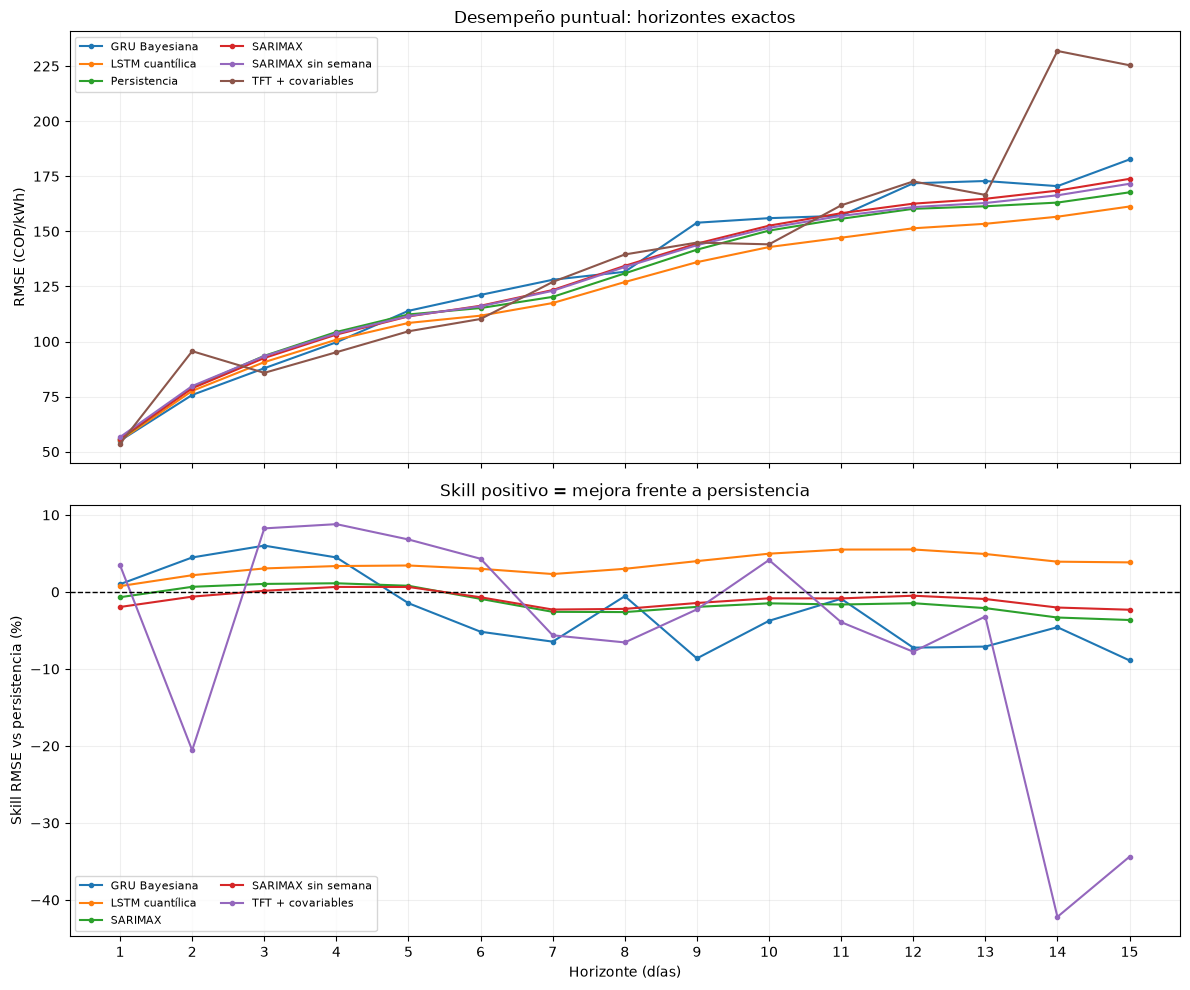

In [4]:
fig,axs=plt.subplots(2,1,figsize=(12,10),sharex=True)
for m,g in met.groupby('Modelo'):
    if m=='Persistencia semanal':continue
    axs[0].plot(g.Horizonte,g.RMSE,marker='o',markersize=3,label=m)
    if m!='Persistencia':axs[1].plot(g.Horizonte,g.Skill_RMSE_pct,marker='o',markersize=3,label=m)
axs[0].set(ylabel='RMSE (COP/kWh)',title='Desempeño puntual: horizontes exactos')
axs[1].axhline(0,color='black',linestyle='--',linewidth=1)
axs[1].set(xlabel='Horizonte (días)',ylabel='Skill RMSE vs persistencia (%)',title='Skill positivo = mejora frente a persistencia')
for a in axs:a.grid(alpha=.2);a.legend(fontsize=8,ncol=2);a.set_xticks(range(1,16))
fig.tight_layout();fig.savefig(OUT/'rmse_y_skill.png',dpi=180);plt.show()


## 3 · Diagnóstico probabilístico: cobertura, amplitud y puntuación de intervalo

Modelo,GRU Bayesiana,LSTM cuantílica,SARIMAX,SARIMAX sin semana,TFT + covariables
Horizonte,,,,,
1,12.3,71.2,85.5,84.9,82.1
2,9.4,51.0,82.3,81.8,68.7
3,10.0,44.4,82.1,82.1,81.2
4,11.1,38.2,81.8,82.1,83.2
5,7.4,36.5,83.5,83.5,87.5
6,10.0,35.6,83.5,83.2,89.7
7,9.7,32.5,82.1,82.9,82.3
8,7.1,31.6,82.1,82.1,83.2
9,4.0,29.9,82.1,81.8,83.5


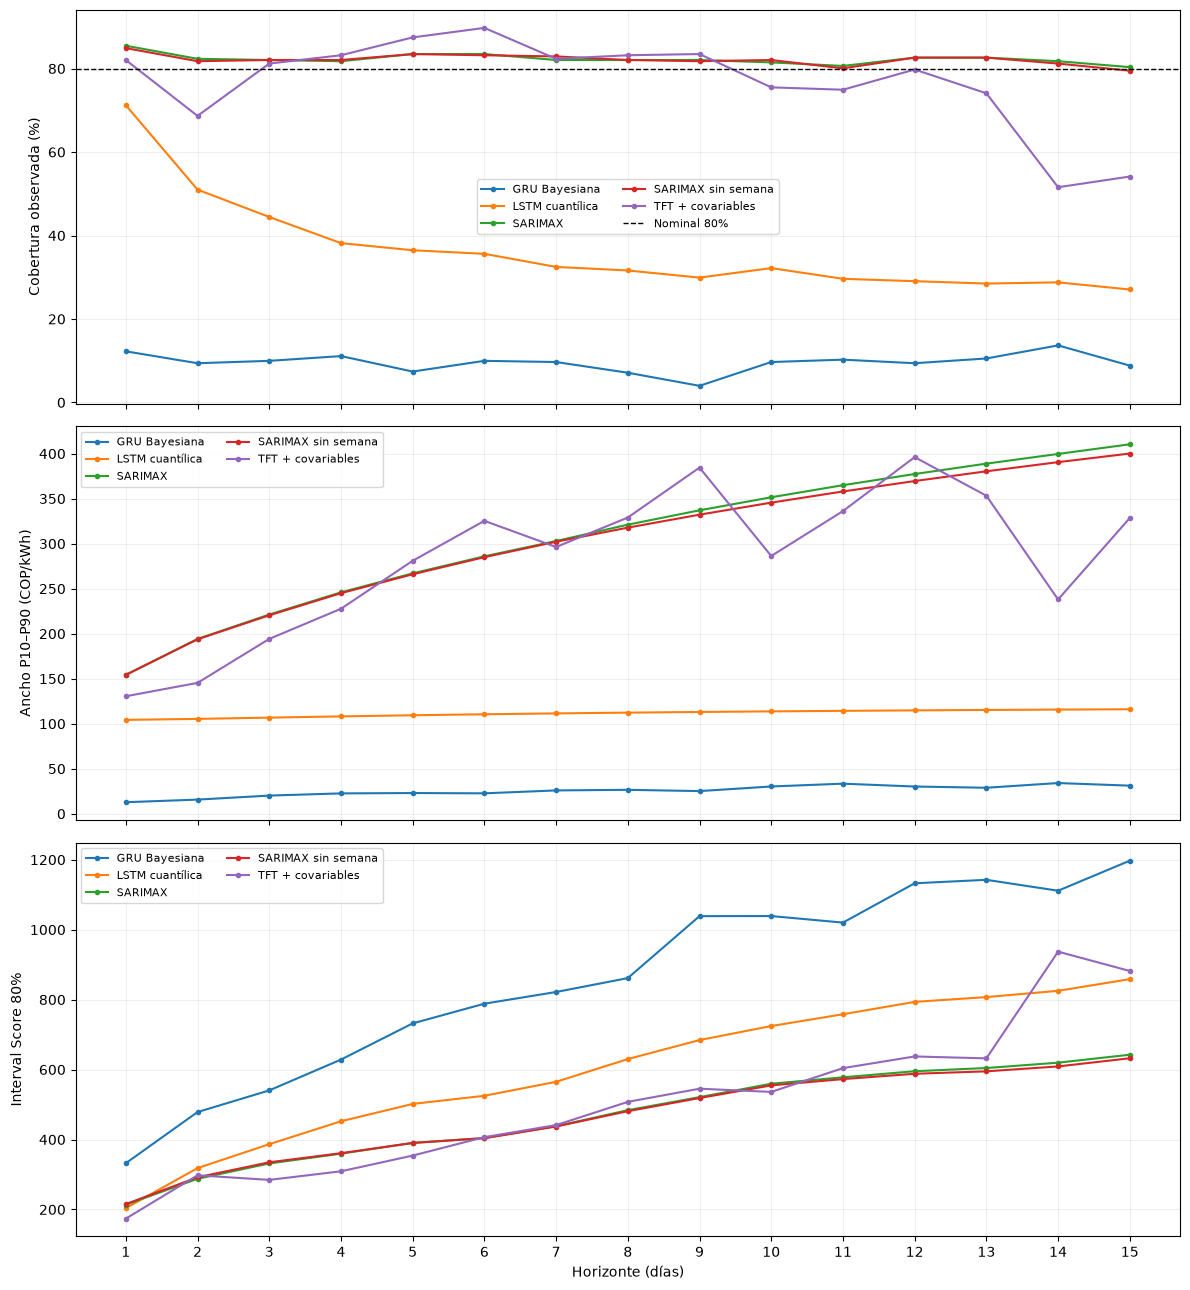

In [5]:
prob=base[~base.Modelo.isin(['Persistencia','Persistencia semanal'])].copy()
assert prob[['p10','p50','p90']].notna().all().all(), 'Faltan cuantiles probabilísticos'
assert (prob.p10<=prob.p50).all() and (prob.p50<=prob.p90).all(), 'Cuantiles desordenados'
assert np.isfinite(prob[['p10','p50','p90']].to_numpy()).all()
prob['dentro80']=(prob.real>=prob.p10)&(prob.real<=prob.p90)
prob['ancho80']=prob.p90-prob.p10
prob['interval_score80']=prob.ancho80+10*(prob.p10-prob.real)*(prob.real<prob.p10)+10*(prob.real-prob.p90)*(prob.real>prob.p90)
cal=prob.groupby(['Modelo','Horizonte'],as_index=False).agg(N=('real','size'),Cobertura80_pct=('dentro80','mean'),Ancho80=('ancho80','mean'),IntervalScore80=('interval_score80','mean'))
cal['Cobertura80_pct']*=100
cal['Brecha_cobertura_pp']=cal.Cobertura80_pct-80
cal.to_csv(OUT/'calibracion_intervalos.csv',index=False)
display(cal.pivot(index='Horizonte',columns='Modelo',values='Cobertura80_pct').round(1))
fig,axs=plt.subplots(3,1,figsize=(12,13),sharex=True)
for m,g in cal.groupby('Modelo'):
    for a,col in zip(axs,['Cobertura80_pct','Ancho80','IntervalScore80']):a.plot(g.Horizonte,g[col],marker='o',markersize=3,label=m)
axs[0].axhline(80,color='black',linestyle='--',linewidth=1,label='Nominal 80%')
for a,lab in zip(axs,['Cobertura observada (%)','Ancho P10–P90 (COP/kWh)','Interval Score 80%']):
    a.set_ylabel(lab);a.grid(alpha=.2);a.legend(fontsize=8,ncol=2)
axs[-1].set_xlabel('Horizonte (días)');axs[-1].set_xticks(range(1,16))
fig.tight_layout();fig.savefig(OUT/'diagnostico_intervalos.png',dpi=180);plt.show()


## 4 · Errores extremos y sensibilidad: ¿pocos días explican el ranking?

In [6]:
err=base.copy();err['error']=err.pred-err.real;err['error_abs']=err.error.abs();err['error_cuad']=err.error**2
res=[]
for (m,h),g in err.groupby(['Modelo','Horizonte']):
    q95=g.error_abs.quantile(.95)
    top=g.nlargest(max(1,int(np.ceil(.05*len(g)))),'error_cuad')
    res.append({'Modelo':m,'Horizonte':h,'RMSE':np.sqrt(g.error_cuad.mean()),
                'RMSE_sin_peor_5pct':np.sqrt(g.nsmallest(len(g)-len(top),'error_cuad').error_cuad.mean()),
                'Participacion_MSE_peor_5pct_pct':100*top.error_cuad.sum()/g.error_cuad.sum(),
                'P95_error_abs':q95})
ext=pd.DataFrame(res)
ext.to_csv(OUT/'sensibilidad_extremos.csv',index=False)
display(ext[ext.Horizonte.isin([1,7,10,14,15])].sort_values(['Horizonte','RMSE']).round(2))
# TFT h=14/15: top errores, fecha, origen, real, pred, ancho y comparación con LSTM
for h in [13,14,15]:
    t=err[(err.Modelo=='TFT + covariables')&(err.Horizonte==h)].nlargest(12,'error_abs')
    print(f'\nTFT h={h} · mayores errores absolutos:')
    display(t[['origen','fecha','real','pred','error','error_abs','p10','p90']].round(2))
    t.to_csv(OUT/f'tft_peores_h{h}.csv',index=False)


,Modelo,Horizonte,RMSE,RMSE_sin_peor_5pct,Participacion_MSE_peor_5pct_pct,P95_error_abs
90,TFT + covariables,1,53.65,42.98,39.10,123.16
0,GRU Bayesiana,1,55.01,41.54,45.89,122.32
15,LSTM cuantílica,1,55.15,42.81,42.84,123.60
30,Persistencia,1,55.57,43.28,42.44,124.66
60,SARIMAX,1,55.95,43.42,42.86,119.37
75,SARIMAX sin semana,1,56.66,44.27,42.07,119.71
45,Persistencia semanal,1,120.07,93.62,42.32,224.87
21,LSTM cuantílica,7,117.48,92.87,40.70,225.02
36,Persistencia,7,120.27,93.89,42.18,224.87
51,Persistencia semanal,7,120.27,93.89,42.18,224.87



TFT h=13 · mayores errores absolutos:


,origen,fecha,real,pred,error,error_abs,p10,p90
30811,2026-05-01,2026-05-14,848.38,159.69,-688.69,688.69,97.55,241.58
30812,2026-05-02,2026-05-15,796.68,149.09,-647.59,647.59,88.80,228.69
30816,2026-05-06,2026-05-19,847.65,243.58,-604.07,604.07,149.83,387.26
30817,2026-05-07,2026-05-20,848.53,248.50,-600.03,600.03,151.06,394.71
30810,2026-04-30,2026-05-13,751.21,193.81,-557.40,557.40,120.70,294.03
30813,2026-05-03,2026-05-16,678.85,157.44,-521.41,521.41,92.24,247.61
30815,2026-05-05,2026-05-18,752.20,231.66,-520.54,520.54,144.83,367.61
30820,2026-05-10,2026-05-23,709.25,190.07,-519.18,519.18,109.95,313.50
30814,2026-05-04,2026-05-17,693.40,183.53,-509.87,509.87,109.73,292.77
30818,2026-05-08,2026-05-21,718.78,279.19,-439.59,439.59,169.12,439.00



TFT h=14 · mayores errores absolutos:


,origen,fecha,real,pred,error,error_abs,p10,p90
31167,2026-05-06,2026-05-20,848.53,153.93,-694.60,694.60,68.71,257.77
31166,2026-05-05,2026-05-19,847.65,153.47,-694.18,694.18,67.46,252.53
31161,2026-04-30,2026-05-14,848.38,157.96,-690.42,690.42,66.77,261.26
31234,2026-07-12,2026-07-26,569.23,1241.20,671.98,671.98,729.35,1584.15
31162,2026-05-01,2026-05-15,796.68,127.05,-669.63,669.63,54.76,210.82
31233,2026-07-11,2026-07-25,681.78,1349.36,667.58,667.58,866.28,1683.15
31235,2026-07-13,2026-07-27,628.17,1293.57,665.41,665.41,843.50,1649.81
31209,2026-06-17,2026-07-01,825.38,181.68,-643.69,643.69,83.69,298.72
31210,2026-06-18,2026-07-02,818.88,185.94,-632.93,632.93,90.60,303.45
31208,2026-06-16,2026-06-30,813.06,188.13,-624.93,624.93,84.87,328.86



TFT h=15 · mayores errores absolutos:


,origen,fecha,real,pred,error,error_abs,p10,p90
31511,2026-04-29,2026-05-14,848.38,185.04,-663.34,663.34,116.01,302.10
31516,2026-05-04,2026-05-19,847.65,201.50,-646.15,646.15,120.66,338.35
31517,2026-05-05,2026-05-20,848.53,211.15,-637.38,637.38,127.84,355.25
31559,2026-06-16,2026-07-01,825.38,193.35,-632.03,632.03,100.20,398.07
31558,2026-06-15,2026-06-30,813.06,190.36,-622.69,622.69,96.71,391.48
31560,2026-06-17,2026-07-02,818.88,199.14,-619.74,619.74,105.95,396.34
31512,2026-04-30,2026-05-15,796.68,180.17,-616.51,616.51,111.68,288.27
31561,2026-06-18,2026-07-03,806.66,203.88,-602.78,602.78,107.65,397.41
31564,2026-06-21,2026-07-06,806.86,222.06,-584.80,584.80,119.12,435.65
31562,2026-06-19,2026-07-04,770.49,195.63,-574.85,574.85,97.55,388.84


## 5 · Comparación pareada con bootstrap en bloques de orígenes

Se remuestrean **bloques consecutivos de orígenes de 14 días**, conservando para cada modelo exactamente las mismas fechas dentro de cada horizonte. La dependencia temporal, especialmente con pronósticos solapados, impide tratar cada error como independiente. Intervalos exploratorios, sensibles al tamaño de bloque y a la no estacionariedad.

In [7]:
rng=np.random.default_rng(20261010)
B=1000; BLOCK=14
# Se compara el diferencial de MSE: negativo favorece al modelo frente a persistencia.
comp=[]
for h in range(1,16):
    g=err[err.Horizonte==h]
    piv=g.pivot(index='origen',columns='Modelo',values='error_cuad').sort_index()
    assert piv.notna().all().all()
    n=len(piv); arr=piv.to_numpy(float); names=list(piv.columns)
    iref=names.index('Persistencia')
    for m in [x for x in names if x not in ('Persistencia','Persistencia semanal')]:
        d=arr[:,names.index(m)]-arr[:,iref]
        vals=np.empty(B)
        for b in range(B):
            starts=rng.integers(0,n,size=int(np.ceil(n/BLOCK)))
            ix=np.concatenate([(s+np.arange(BLOCK))%n for s in starts])[:n]
            vals[b]=d[ix].mean()
        lo,hi=np.quantile(vals,[.025,.975]);obs=d.mean()
        comp.append({'Modelo':m,'Horizonte':h,'Delta_MSE_vs_persistencia':obs,
                     'IC95_inf':lo,'IC95_sup':hi,
                     'Lectura_exploratoria':'mejora' if hi<0 else ('empeora' if lo>0 else 'no concluyente')})
boot=pd.DataFrame(comp)
boot.to_csv(OUT/'bootstrap_bloques_delta_mse.csv',index=False)
display(boot[boot.Horizonte.isin([1,3,5,7,10,14,15])].round(2))


,Modelo,Horizonte,Delta_MSE_vs_persistencia,IC95_inf,IC95_sup,Lectura_exploratoria
0,GRU Bayesiana,1,-61.94,-241.35,119.25,no concluyente
1,LSTM cuantílica,1,-46.52,-126.91,27.53,no concluyente
2,SARIMAX,1,42.39,-164.47,308.22,no concluyente
3,SARIMAX sin semana,1,121.78,-73.18,395.33,no concluyente
4,TFT + covariables,1,-209.95,-533.30,110.96,no concluyente
10,GRU Bayesiana,3,-1019.78,-1882.76,-213.40,mejora
11,LSTM cuantílica,3,-525.53,-1137.19,62.03,no concluyente
12,SARIMAX,3,-181.20,-696.96,368.50,no concluyente
13,SARIMAX sin semana,3,-26.25,-530.91,543.37,no concluyente
14,TFT + covariables,3,-1383.56,-2294.44,-483.53,mejora


## 6 · Contraste estacional y escenarios oracle (separados)

In [8]:
s=met[met.Modelo.isin(['SARIMAX','SARIMAX sin semana','Persistencia semanal'])]
display(s.pivot(index='Horizonte',columns='Modelo',values='RMSE').round(2))
if oracle:
    orows=[]
    for (m,h),g in df[df.Modelo.isin(oracle)].groupby(['Modelo','Horizonte']):orows.append({'Modelo':m,'Horizonte':h,**metrics(g)})
    oracle_met=pd.DataFrame(orows)
    oracle_met.to_csv(OUT/'metricas_oracle_separadas.csv',index=False)
    display(oracle_met.pivot(index='Horizonte',columns='Modelo',values='RMSE').round(2))
else:print('No hay predicciones oracle en el archivo.')


Modelo,Persistencia semanal,SARIMAX,SARIMAX sin semana
Horizonte,,,
1,120.07,55.95,56.66
2,120.04,78.79,79.81
3,120.05,92.53,93.37
4,120.06,103.17,103.66
5,120.11,111.40,111.58
6,120.08,116.24,116.00
7,120.27,123.38,123.02
8,161.77,134.36,133.82
9,161.80,144.45,143.73


Modelo,SARIMAX [oracle],SARIMAX sin semana [oracle]
Horizonte,,
1,47.22,47.55
2,63.99,64.31
3,75.40,75.47
4,84.30,84.03
5,91.32,90.76
6,97.96,97.19
7,105.52,104.67
8,114.14,112.96
9,121.02,119.55


## 7 · Resumen automático y límites de inferencia

In [9]:
best=met[met.Modelo.isin(['SARIMAX','LSTM cuantílica','TFT + covariables','GRU Bayesiana'])].sort_values(['Horizonte','RMSE']).groupby('Horizonte').first().reset_index()
best[['Horizonte','Modelo','RMSE','Skill_RMSE_pct']].to_csv(OUT/'ganadores_por_horizonte.csv',index=False)
print('GANADORES PUNTUALES POR HORIZONTE (entre cuatro modelos):')
display(best[['Horizonte','Modelo','RMSE','Skill_RMSE_pct']].round(2))
print('\nRESUMEN DE COBERTURA MEDIA POR MODELO:')
display(cal.groupby('Modelo')[['Cobertura80_pct','Ancho80','IntervalScore80']].mean().round(2))
print('\nArchivos guardados en:',OUT)
print('IMPORTANTE: 1) Comparaciones sobre mismo origen/fecha, no prueba causal. 2) Oracle separado.')
print('3) LSTM cuantiles plug-in y GRU bayesiana no equivalen a incertidumbre predictiva completa.')
print('4) Bootstrap exploratorio; comparar sensibilidad a BLOCK=7,14,30 antes de concluir.')
print('5) TFT h=14/15: revisar errores extremos, estabilidad por semilla y entrenamiento si procede.')


GANADORES PUNTUALES POR HORIZONTE (entre cuatro modelos):


,Horizonte,Modelo,RMSE,Skill_RMSE_pct
0,1,TFT + covariables,53.65,3.46
1,2,GRU Bayesiana,75.77,4.48
2,3,TFT + covariables,85.79,8.25
3,4,TFT + covariables,95.16,8.80
4,5,TFT + covariables,104.65,6.81
5,6,TFT + covariables,110.24,4.31
6,7,LSTM cuantílica,117.48,2.32
7,8,LSTM cuantílica,127.00,3.00
8,9,LSTM cuantílica,136.03,4.00
9,10,LSTM cuantílica,142.88,4.97



RESUMEN DE COBERTURA MEDIA POR MODELO:


,Cobertura80_pct,Ancho80,IntervalScore80
Modelo,,,
GRU Bayesiana,9.55,25.56,857.62
LSTM cuantílica,36.41,111.44,602.26
SARIMAX,82.28,308.16,468.62
SARIMAX sin semana,82.15,304.06,465.73
TFT + covariables,76.75,283.50,503.28



Archivos guardados en: /Users/maguverm/Documents/tesis-bolsa/reports/auditoria_predicciones_guardadas
IMPORTANTE: 1) Comparaciones sobre mismo origen/fecha, no prueba causal. 2) Oracle separado.
3) LSTM cuantiles plug-in y GRU bayesiana no equivalen a incertidumbre predictiva completa.
4) Bootstrap exploratorio; comparar sensibilidad a BLOCK=7,14,30 antes de concluir.
5) TFT h=14/15: revisar errores extremos, estabilidad por semilla y entrenamiento si procede.


### Qué entregarle al profesor

Primero revisar `metricas_y_skill.csv`, `calibracion_intervalos.csv`, `sensibilidad_extremos.csv` y `bootstrap_bloques_delta_mse.csv`. La tabla de ganadores **no** debe interpretarse como superioridad estadística sin examinar los intervalos pareados.

**No se entrenó ningún modelo.** Si el archivo `predicciones_todos.parquet` no está disponible en el repositorio local, el notebook se detendrá sin iniciar ningún entrenamiento.